# 20 — Modelos: SVM, Bagging, Boosting, Stacking e hiperparámetros
Con el conjunto preparado en el 19 (808 procesos y sus 28 variables) se entrenan los modelos del punto **2** del informe.
Cada modelo recibe los datos de un proceso y devuelve **cuántos días tardaría su fila** (en logaritmo; se convierte a
días al final). Todo se hace **solo con el 80 % de entrenamiento**, usando **validación cruzada de 5 pliegues**: se parte
el entrenamiento en 5 trozos, se entrena con 4 y se mide con el quinto, cinco veces. El 20 % de prueba no se toca hasta el 21.

| modelo | familia | idea en una línea |
|---|---|---|
| Línea base | referencia | siempre dice el tiempo promedio: el piso que cualquier modelo debe superar |
| Fórmula ingenua | referencia | stock heredado ÷ ingresos × 365: lo que diría una cuenta rápida, sin aprender nada |
| Regresión lineal (Ridge) | referencia | una suma ponderada de las variables, con freno a los pesos grandes |
| **SVM** (SVR) | SVM | busca una curva que deje a la mayoría de los procesos dentro de un **tubo** de ancho ε; el *kernel* RBF la deja curvarse |
| **Bagging** | Bagging | muchos árboles, cada uno con una **muestra con reemplazo**; se **promedian** |
| **Random Forest** | Bagging | bagging + cada corte del árbol mira solo **algunas variables** al azar |
| **AdaBoost** | Boosting | árboles **en secuencia**; cada uno da más peso a los procesos que el anterior estimó peor |
| **Gradient Boosting** | Boosting | árboles en secuencia; cada uno corrige el **error residual** del conjunto anterior |
| **Stacking** | Stacking | SVM + Random Forest + Gradient Boosting, y una regresión lineal que aprende **a combinarlos** |

**Cómo se mide el error.** El modelo trabaja en $\log(1 + \text{días})$, así que la métrica principal es el **error
absoluto medio en log** (MAE): equivocarse por el doble pesa lo mismo en un proceso de 30 días que en uno de 900. Se
reportan además tres lecturas para la gente:

- **dentro del doble:** de cada 100 procesos, en cuántos el tiempo real quedó entre la mitad y el doble de lo estimado;
- **factor mediano:** la mitad de las estimaciones se equivoca por menos que este factor (×1,5 = hasta 50 % de más o de menos);
- **R²:** qué parte de las diferencias de tiempo entre procesos explica el modelo (0 = nada, 1 = todo).

In [1]:
%run -i modulos/comun.ipynb
%run -i modulos/modelado.ipynb
import time
import warnings
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_validate

warnings.filterwarnings("ignore", category=FutureWarning)
datos = cargar_conjunto()
part = pd.read_csv(MODELO_DIR / "particion.csv")
assert np.allclose(part[OBJETIVO].to_numpy(), datos[OBJETIVO].to_numpy()), "la partición no corresponde a estos datos"
tr = part.index[part["particion"] == "entrenamiento"]
X_tr, y_tr = datos.loc[tr, COMPLETA], datos.loc[tr, OBJETIVO]
print(len(X_tr), "filas de entrenamiento,", X_tr.shape[1], "variables")
METRICAS = {
    "mae_log": "neg_mean_absolute_error",
    "r2_log": "r2",
    "dentro_doble": make_scorer(lambda a, b: float((np.abs(np.asarray(b) - np.asarray(a)) <= np.log(2)).mean())),
    "factor_mediano": make_scorer(lambda a, b: float(np.exp(np.median(np.abs(np.asarray(b) - np.asarray(a)))))),
}


def evaluar_cv(m):
    r = cross_validate(m, X_tr, y_tr, cv=CV5, scoring=METRICAS, n_jobs=-1)
    out = {k: r[f"test_{k}"].mean() for k in METRICAS}
    out["mae_log"] = -out["mae_log"]
    out["mae_log_desvio"] = r["test_mae_log"].std()
    return out

646 filas de entrenamiento, 28 variables


## Paso 1: todos los modelos con sus valores por defecto

In [2]:
filas = []
for nombre in MODELOS:
    t0 = time.time()
    res = evaluar_cv(modelo(nombre, COMPLETA))
    filas.append({"modelo": nombre, "familia": FAMILIAS[nombre][0], "configuracion": "por defecto", **res,
                  "segundos": time.time() - t0})
defecto = pd.DataFrame(filas)
display(defecto.round(3))
assert abs(defecto.loc[defecto["modelo"] == "Línea base (promedio)", "r2_log"].iloc[0]) < 0.05

,modelo,familia,configuracion,mae_log,r2_log,dentro_doble,factor_mediano,mae_log_desvio,segundos
0,Línea base (promedio),referencia,por defecto,1.085,-0.016,0.430,2.299,0.120,3.641
1,Fórmula ingenua,referencia,por defecto,0.888,0.046,0.584,1.716,0.044,2.762
2,Regresión lineal (Ridge),referencia,por defecto,0.796,0.362,0.601,1.695,0.096,2.898
3,SVM,SVM,por defecto,0.790,0.374,0.618,1.654,0.096,1.948
4,Bagging,Bagging,por defecto,0.804,0.356,0.591,1.708,0.061,0.312
5,Random Forest,Bagging,por defecto,0.767,0.416,0.611,1.643,0.078,0.521
6,AdaBoost,Boosting,por defecto,0.890,0.276,0.531,1.878,0.082,0.222
7,Gradient Boosting,Boosting,por defecto,0.780,0.384,0.608,1.682,0.079,0.254
8,Stacking,Stacking,por defecto,0.751,0.443,0.619,1.636,0.079,3.035


## Paso 2: ajuste de hiperparámetros
Un **hiperparámetro** es una perilla que se fija *antes* de entrenar (cuántos árboles, qué tan profundos, cuánto
castigar los errores). No se aprende de los datos: se elige probando combinaciones con validación cruzada, y gana la que
deja el **menor error absoluto medio**.

- **SVM: búsqueda en grilla** (`GridSearchCV`). Tres perillas: `C` (cuánto castiga los procesos que quedan fuera del
  tubo; alto = curva más ajustada), `gamma` (qué tan lejos llega la influencia de cada punto; alto = curva más
  ondulada) y `epsilon` (el ancho del tubo: errores menores que eso no se castigan). Se prueban las 48 combinaciones.
- **Resto: búsqueda aleatoria** (`RandomizedSearchCV`, 30 combinaciones al azar): con 4 o 5 perillas la grilla completa
  tendría cientos de combinaciones, y la búsqueda aleatoria encuentra valores casi igual de buenos con mucho menos costo.

In [3]:
GRILLA_SVM = {"modelo__C": [0.1, 1, 10, 100], "modelo__gamma": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3],
              "modelo__epsilon": [0.1, 0.5]}
ESPACIOS = {
    "Regresión lineal (Ridge)": {"modelo__alpha": list(np.logspace(-2, 3, 11))},
    "Bagging": {"modelo__n_estimators": [50, 100, 200, 400], "modelo__max_samples": [0.5, 0.7, 1.0],
                "modelo__max_features": [0.5, 0.7, 1.0], "modelo__estimator__min_samples_leaf": [1, 3, 5, 10]},
    "Random Forest": {"modelo__n_estimators": [200, 400, 600], "modelo__max_depth": [None, 4, 6, 8, 12],
                      "modelo__min_samples_leaf": [1, 2, 4, 8], "modelo__max_features": ["sqrt", 0.3, 0.5, 1.0]},
    "AdaBoost": {"modelo__n_estimators": [50, 100, 200, 400], "modelo__learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0],
                 "modelo__estimator__max_depth": [2, 3, 4, 6], "modelo__loss": ["linear", "square", "exponential"]},
    "Gradient Boosting": {"modelo__n_estimators": [100, 200, 400], "modelo__learning_rate": [0.01, 0.03, 0.05, 0.1],
                          "modelo__max_depth": [2, 3, 4], "modelo__subsample": [0.7, 0.85, 1.0],
                          "modelo__min_samples_leaf": [1, 5, 10],
                          "modelo__loss": ["squared_error", "absolute_error", "huber"]},
}


def limpio(params):
    """Quita el prefijo del pipeline y convierte los tipos de numpy para guardarlos en JSON."""
    out = {}
    for k, v in params.items():
        if isinstance(v, np.generic):
            v = v.item()
        out[k.replace("modelo__", "", 1)] = v
    return out


hp, busquedas = {}, {}
t0 = time.time()
busquedas["SVM"] = GridSearchCV(modelo("SVM", COMPLETA), GRILLA_SVM, cv=CV5, scoring=ESCORE, n_jobs=-1).fit(X_tr, y_tr)
hp["SVM"] = limpio(busquedas["SVM"].best_params_)
for nombre, espacio in ESPACIOS.items():
    b = RandomizedSearchCV(modelo(nombre, COMPLETA), espacio, n_iter=min(30, int(np.prod([len(v) for v in espacio.values()]))),
                           cv=CV5, scoring=ESCORE, random_state=SEMILLA, n_jobs=-1).fit(X_tr, y_tr)
    busquedas[nombre], hp[nombre] = b, limpio(b.best_params_)
print(f"búsqueda: {time.time() - t0:.0f} s")
(MODELO_DIR / "hiperparametros.json").write_text(json.dumps(hp, indent=2, ensure_ascii=False), encoding="utf-8")
for nombre, p in hp.items():
    print(f"{nombre:26s} MAE log {-busquedas[nombre].best_score_:.3f}  {p}")

búsqueda: 45 s
SVM                        MAE log 0.751  {'C': 10, 'epsilon': 0.1, 'gamma': 0.01}
Regresión lineal (Ridge)   MAE log 0.787  {'alpha': 10.0}
Bagging                    MAE log 0.752  {'n_estimators': 200, 'max_samples': 0.5, 'max_features': 1.0, 'estimator__min_samples_leaf': 1}
Random Forest              MAE log 0.752  {'n_estimators': 400, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 8}
AdaBoost                   MAE log 0.755  {'n_estimators': 100, 'loss': 'exponential', 'learning_rate': 0.05, 'estimator__max_depth': 6}
Gradient Boosting          MAE log 0.746  {'subsample': 0.85, 'n_estimators': 100, 'min_samples_leaf': 10, 'max_depth': 4, 'loss': 'huber', 'learning_rate': 0.03}


La grilla del SVM se puede mirar: cada celda es el error de validación cruzada para un par (`C`, `gamma`), con el mejor
`epsilon` de los dos probados.

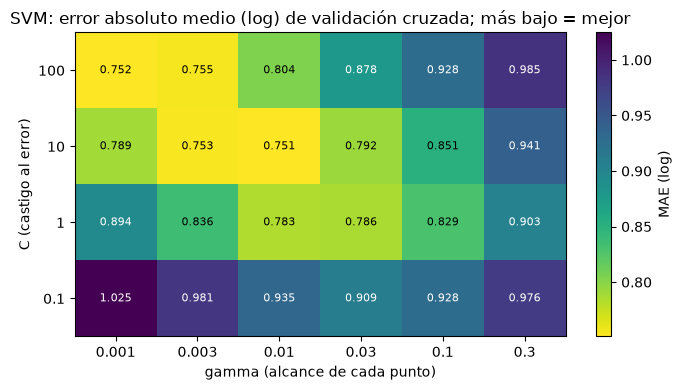

In [4]:
res_svm = pd.DataFrame(busquedas["SVM"].cv_results_)
res_svm["mae_log"] = -res_svm["mean_test_score"]
mapa = res_svm.pivot_table(index="param_modelo__C", columns="param_modelo__gamma", values="mae_log", aggfunc="min")
mapa.to_csv(MODELO_DIR / "grilla_svm.csv")
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(mapa.values, cmap="viridis_r", aspect="auto", origin="lower")
ax.set_xticks(range(mapa.shape[1]), [f"{g:g}" for g in mapa.columns])
ax.set_yticks(range(mapa.shape[0]), [f"{c:g}" for c in mapa.index])
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8, color="white" if v > mapa.values.mean() else "black")
ax.set_xlabel("gamma (alcance de cada punto)")
ax.set_ylabel("C (castigo al error)")
ax.set_title("SVM: error absoluto medio (log) de validación cruzada; más bajo = mejor")
fig.colorbar(im, ax=ax, label="MAE (log)")
plt.tight_layout()
guardar_figura(fig, "nb20_2.png")
plt.show()

## Paso 3: los modelos ajustados (y el Stacking armado con los mejores SVM, Random Forest y Gradient Boosting)
Se vuelve a medir cada modelo con sus hiperparámetros elegidos, con la misma validación cruzada. El Stacking no tiene
búsqueda propia: combina las versiones ajustadas de sus tres modelos base, y su regresión lineal final aprende cuánto
confiar en cada uno usando predicciones *fuera de pliegue* (nunca las del mismo dato con el que se entrenó).

In [5]:
filas = []
for nombre in MODELOS:
    t0 = time.time()
    res = evaluar_cv(modelo(nombre, COMPLETA, hp))
    filas.append({"modelo": nombre, "familia": FAMILIAS[nombre][0], "configuracion": "ajustado", **res,
                  "segundos": time.time() - t0})
ajustado = pd.DataFrame(filas)
metricas_cv = pd.concat([defecto, ajustado], ignore_index=True)
metricas_cv.to_csv(MODELO_DIR / "metricas_cv.csv", index=False)
comparacion = (metricas_cv.pivot_table(index="modelo", columns="configuracion", values="mae_log")
               .reindex(MODELOS)[["por defecto", "ajustado"]])
comparacion["mejora"] = comparacion["por defecto"] - comparacion["ajustado"]
display(comparacion.round(3))
display(ajustado.set_index("modelo")[["mae_log", "mae_log_desvio", "dentro_doble", "factor_mediano", "r2_log"]].round(3))

configuracion,por defecto,ajustado,mejora
modelo,,,
Línea base (promedio),1.085,1.085,0.000
Fórmula ingenua,0.888,0.888,0.000
Regresión lineal (Ridge),0.796,0.787,0.009
SVM,0.790,0.751,0.039
Bagging,0.804,0.752,0.052
Random Forest,0.767,0.752,0.015
AdaBoost,0.890,0.755,0.135
Gradient Boosting,0.780,0.746,0.034
Stacking,0.751,0.738,0.013


,mae_log,mae_log_desvio,dentro_doble,factor_mediano,r2_log
modelo,,,,,
Línea base (promedio),1.085,0.120,0.430,2.299,-0.016
Fórmula ingenua,0.888,0.044,0.584,1.716,0.046
Regresión lineal (Ridge),0.787,0.093,0.614,1.697,0.384
SVM,0.751,0.092,0.636,1.645,0.441
Bagging,0.752,0.083,0.622,1.583,0.429
Random Forest,0.752,0.076,0.630,1.652,0.430
AdaBoost,0.755,0.067,0.632,1.644,0.399
Gradient Boosting,0.746,0.080,0.653,1.605,0.438
Stacking,0.738,0.088,0.644,1.639,0.457


In [6]:
hp_tabla = pd.DataFrame([{"modelo": m, "hiperparametro": k, "valor": v} for m, p in hp.items() for k, v in p.items()])
hp_tabla.to_csv(MODELO_DIR / "hiperparametros.csv", index=False)
mejor = ajustado.loc[ajustado["mae_log"].idxmin(), "modelo"]
print("mejor modelo en validación cruzada:", mejor, round(ajustado["mae_log"].min(), 3))
# Controles: todos los modelos entrenados superan a la línea base y a la fórmula ingenua.
ref = ajustado.set_index("modelo")["mae_log"]
assert (ref[ENTRENABLES] < ref["Línea base (promedio)"]).all()
assert set(hp) == set(ENTRENABLES) - {"Stacking"}

mejor modelo en validación cruzada: Stacking 0.738


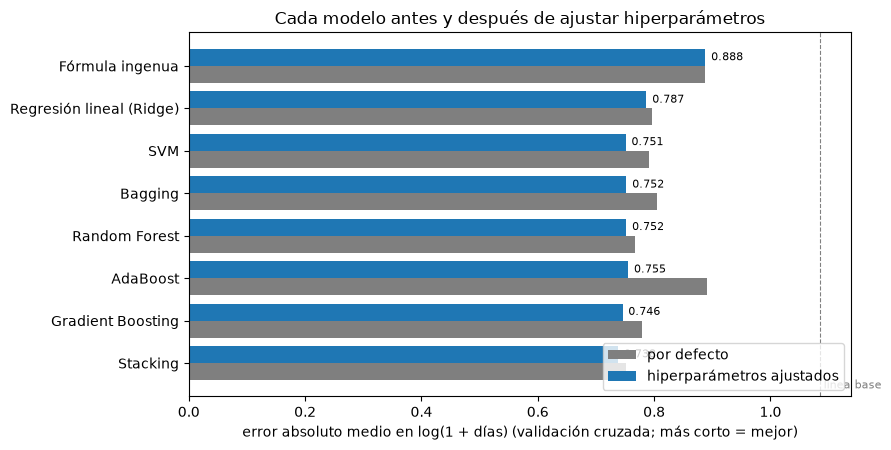

In [7]:
orden = [m for m in MODELOS if m != "Línea base (promedio)"]
fig, ax = plt.subplots(figsize=(9, 4.6))
pos = np.arange(len(orden))
ax.barh(pos + 0.2, comparacion.loc[orden, "por defecto"], 0.4, color="tab:gray", label="por defecto")
ax.barh(pos - 0.2, comparacion.loc[orden, "ajustado"], 0.4, color="tab:blue", label="hiperparámetros ajustados")
for i, m in enumerate(orden):
    ax.text(comparacion.loc[m, "ajustado"] + 0.01, i - 0.2, f"{comparacion.loc[m, 'ajustado']:.3f}", va="center", fontsize=8)
base = comparacion.loc["Línea base (promedio)", "ajustado"]
ax.axvline(base, color="gray", ls="--", lw=0.8)
ax.text(base, len(orden) - 0.4, " línea base", fontsize=8, color="gray")
ax.set_yticks(pos, orden)
ax.invert_yaxis()
ax.set_xlabel("error absoluto medio en log(1 + días) (validación cruzada; más corto = mejor)")
ax.set_title("Cada modelo antes y después de ajustar hiperparámetros")
ax.legend(loc="lower right")
plt.tight_layout()
guardar_figura(fig, "nb20_1.png")
plt.show()

## Lectura
- **Todos los modelos entrenados superan a las dos referencias.** La línea base (decir siempre el promedio) tiene un error
  de 1,085 en log y la fórmula ingenua 0,888; el mejor modelo baja a **0,738** (Stacking). En días: con la fórmula
  ingenua la mitad de las estimaciones se equivoca por menos de ×1,72; con el Stacking, por menos de ×1,64, y el 64 % de
  los procesos queda entre la mitad y el doble de lo estimado (la línea base: 43 %).
- **La ganancia grande no es «acertar más veces dentro del doble», es no fallar por mucho.** La fórmula ingenua ya deja al
  58 % dentro del doble, pero explica casi nada de las diferencias entre procesos (R² 0,05) porque en los procesos con mucha
  fila se queda muy corta. Los modelos explican alrededor del 40 % (R² en log entre 0,38 y 0,46).
- **Seis modelos empatan arriba:** Stacking 0,738, Gradient Boosting 0,746, SVM 0,751, Bagging y Random Forest 0,752,
  AdaBoost 0,755. Las diferencias (≤ 0,02) son menores que el desvío entre pliegues (≈ 0,08): con 646 procesos **no se puede
  decir que uno sea claramente mejor**. El notebook 21 toma al Stacking como «mejor modelo» porque es el de menor error.
- **La regresión lineal (Ridge) queda atrás** (0,787): parte de la relación entre carga y tiempo no es una suma de efectos.
- **Ajustar hiperparámetros ayuda a todos**, sobre todo a AdaBoost (0,890 → 0,755: con árboles de profundidad 6 y una tasa
  de aprendizaje baja deja de perseguir los procesos raros) y a Bagging (0,804 → 0,752: usar la mitad de las filas por árbol).
  Gradient Boosting eligió la pérdida **Huber**, que trata los errores grandes como lineales y no cuadráticos: así unos
  pocos procesos extremos no arrastran a los demás.
- **SVM:** la grilla va de 1,025 a 0,751. El mejor punto es `C = 10`, `gamma = 0,01`, `epsilon = 0,1`: una curva suave con
  un castigo moderado. Con gamma alto (curva muy ondulada) el error sube: el SVM sobreajusta.
- **Stacking apenas mejora a sus componentes** (0,738 contra 0,746-0,752): los tres modelos base aprenden casi lo mismo.